# 01 - Dry Bean Classification
**AIN3101 Machine Learning Project** - Badr University in Assiut, Fall 2026

Classification of 7 dry bean types with Logistic Regression, Random Forest and SVM.

Dataset: Dry Bean (UCI id=602), Koklu & Özkan (2020), license CC BY 4.0.

In [1]:
import sys
sys.path.append("..")   # so we can import src/utils.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder

from src.utils import *

pd.set_option("display.max_columns", 30)

## Stage 1: Understand the problem and the features
The task is **multiclass classification**: predict the bean type (`Class`, 7 types) from 16 numeric
features measured on images of the grains.

- 12 dimension features: Area, Perimeter, MajorAxisLength, MinorAxisLength, AspectRation, Eccentricity,
  ConvexArea, EquivDiameter, Extent, Solidity, roundness, Compactness
- 4 shape features: ShapeFactor1 to ShapeFactor4

Note: `AspectRation` and `roundness` are spelled like this in the file, so we keep these names.

In [2]:
df = pd.read_excel("../data/dry_bean/Dry_Bean_Dataset.xlsx")
df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [3]:
# the citation requested by the authors (second sheet of the xlsx file)
print(pd.read_excel("../data/dry_bean/Dry_Bean_Dataset.xlsx", sheet_name="Citation_Request", header=None).iloc[0, 0])

Citation Request :
KOKLU, M. and OZKAN, I.A., (2020), “Multiclass Classification of Dry Beans Using Computer Vision and Machine Learning Techniques.” Computers and Electronics in Agriculture, 174, 105507. DOI: https://doi.org/10.1016/j.compag.2020.105507


## Stage 2: Quality check

In [4]:
quality_check(df)

Shape: (13611, 17)
Missing values: 0
Duplicate rows: 68

Data types:
float64    14
int64       2
str         1
Name: count, dtype: int64


In [5]:
# which classes do the duplicates belong to?
print("Duplicates per class:")
print(df[df.duplicated()]["Class"].value_counts())

Duplicates per class:
Class
HOROZ    68
Name: count, dtype: int64


All duplicates are exact full-row copies and all of them are in the HOROZ class.
We remove them **before** the split, otherwise the same row could end up in both the training and the test set (data leakage).

In [6]:
counts_before = df["Class"].value_counts()

df = df.drop_duplicates().reset_index(drop=True)
counts_after = df["Class"].value_counts()

class_table = pd.DataFrame({"Raw count": counts_before,
                            "After cleaning": counts_after,
                            "Share after cleaning (%)": (counts_after / len(df) * 100).round(1)})
print("Rows after cleaning:", len(df))
class_table

Rows after cleaning: 13543


,Raw count,After cleaning,Share after cleaning (%)
Class,,,
DERMASON,3546,3546,26.2
SIRA,2636,2636,19.5
SEKER,2027,2027,15.0
HOROZ,1928,1860,13.7
CALI,1630,1630,12.0
BARBUNYA,1322,1322,9.8
BOMBAY,522,522,3.9


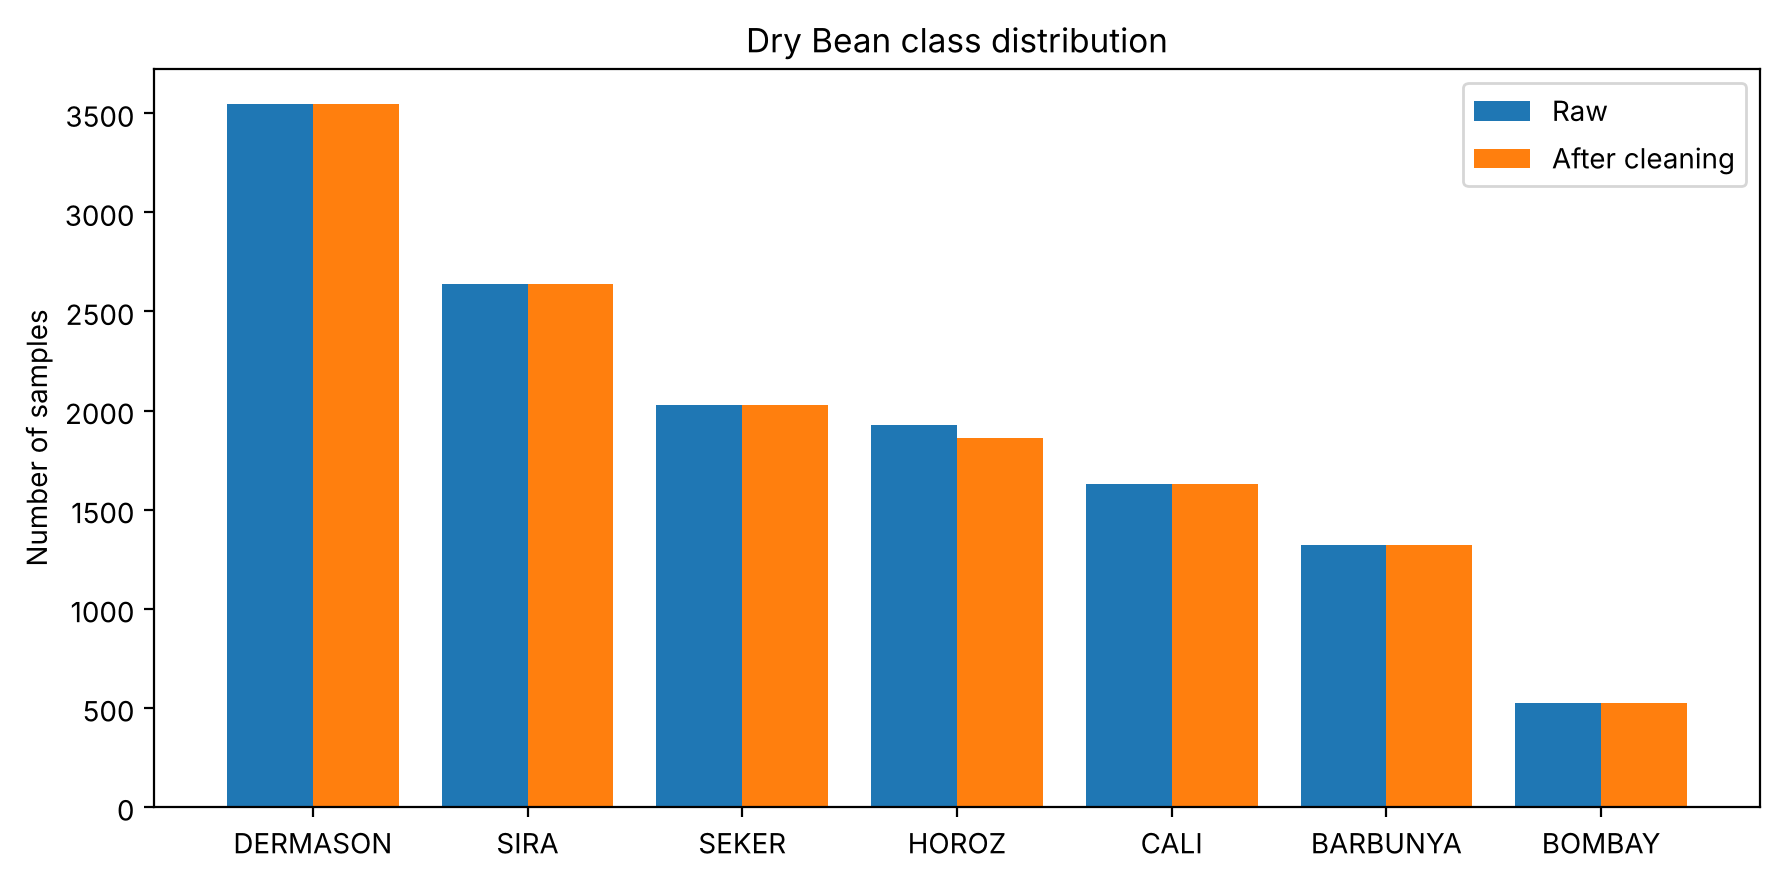

In [7]:
# fig01: class distribution before and after removing duplicates
x = np.arange(len(class_table))
plt.figure(figsize=(9, 4.5))
plt.bar(x - 0.2, class_table["Raw count"], width=0.4, label="Raw")
plt.bar(x + 0.2, class_table["After cleaning"], width=0.4, label="After cleaning")
plt.xticks(x, class_table.index)
plt.ylabel("Number of samples")
plt.title("Dry Bean class distribution")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR + "fig01_drybean_class_distribution.png", dpi=150)
plt.show()

## Stage 3: Train/test split
80% train / 20% test, `stratify=y` so every class keeps the same share in both sets
(important because BOMBAY is only 3.9% of the data), and `random_state=42` so the split is reproducible.
The test set is used only once, at the end.

In [8]:
X = df.drop(columns="Class")
y_names = df["Class"]

# encode the class names as numbers (0..6)
encoder = LabelEncoder()
y = encoder.fit_transform(y_names)
class_names = encoder.classes_
print(dict(zip(class_names, range(len(class_names)))))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, " Test:", X_test.shape)

{'BARBUNYA': 0, 'BOMBAY': 1, 'CALI': 2, 'DERMASON': 3, 'HOROZ': 4, 'SEKER': 5, 'SIRA': 6}
Train: (10834, 16)  Test: (2709, 16)


## Stage 4: EDA (training set only)
We look only at the training set so that nothing about the test set influences our decisions.

In [9]:
X_train.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Area,10834.0,53017.520,29355.865,20420.000,36275.750,44606.500,61427.250,248424.000
Perimeter,10834.0,854.636,214.484,524.736,703.030,793.880,975.996,1895.940
MajorAxisLength,10834.0,319.786,85.722,183.601,253.073,296.523,375.904,726.373
MinorAxisLength,10834.0,202.324,45.048,122.513,175.857,192.534,217.072,460.198
AspectRation,10834.0,1.581,0.245,1.025,1.432,1.550,1.703,2.430
Eccentricity,10834.0,0.750,0.092,0.219,0.716,0.764,0.809,0.911
ConvexArea,10834.0,53736.120,29803.052,20684.000,36678.000,45131.500,62397.000,251082.000
EquivDiameter,10834.0,252.964,59.274,161.244,214.913,238.317,279.663,562.408
Extent,10834.0,0.750,0.049,0.555,0.719,0.760,0.787,0.866
Solidity,10834.0,0.987,0.005,0.919,0.986,0.988,0.990,0.995


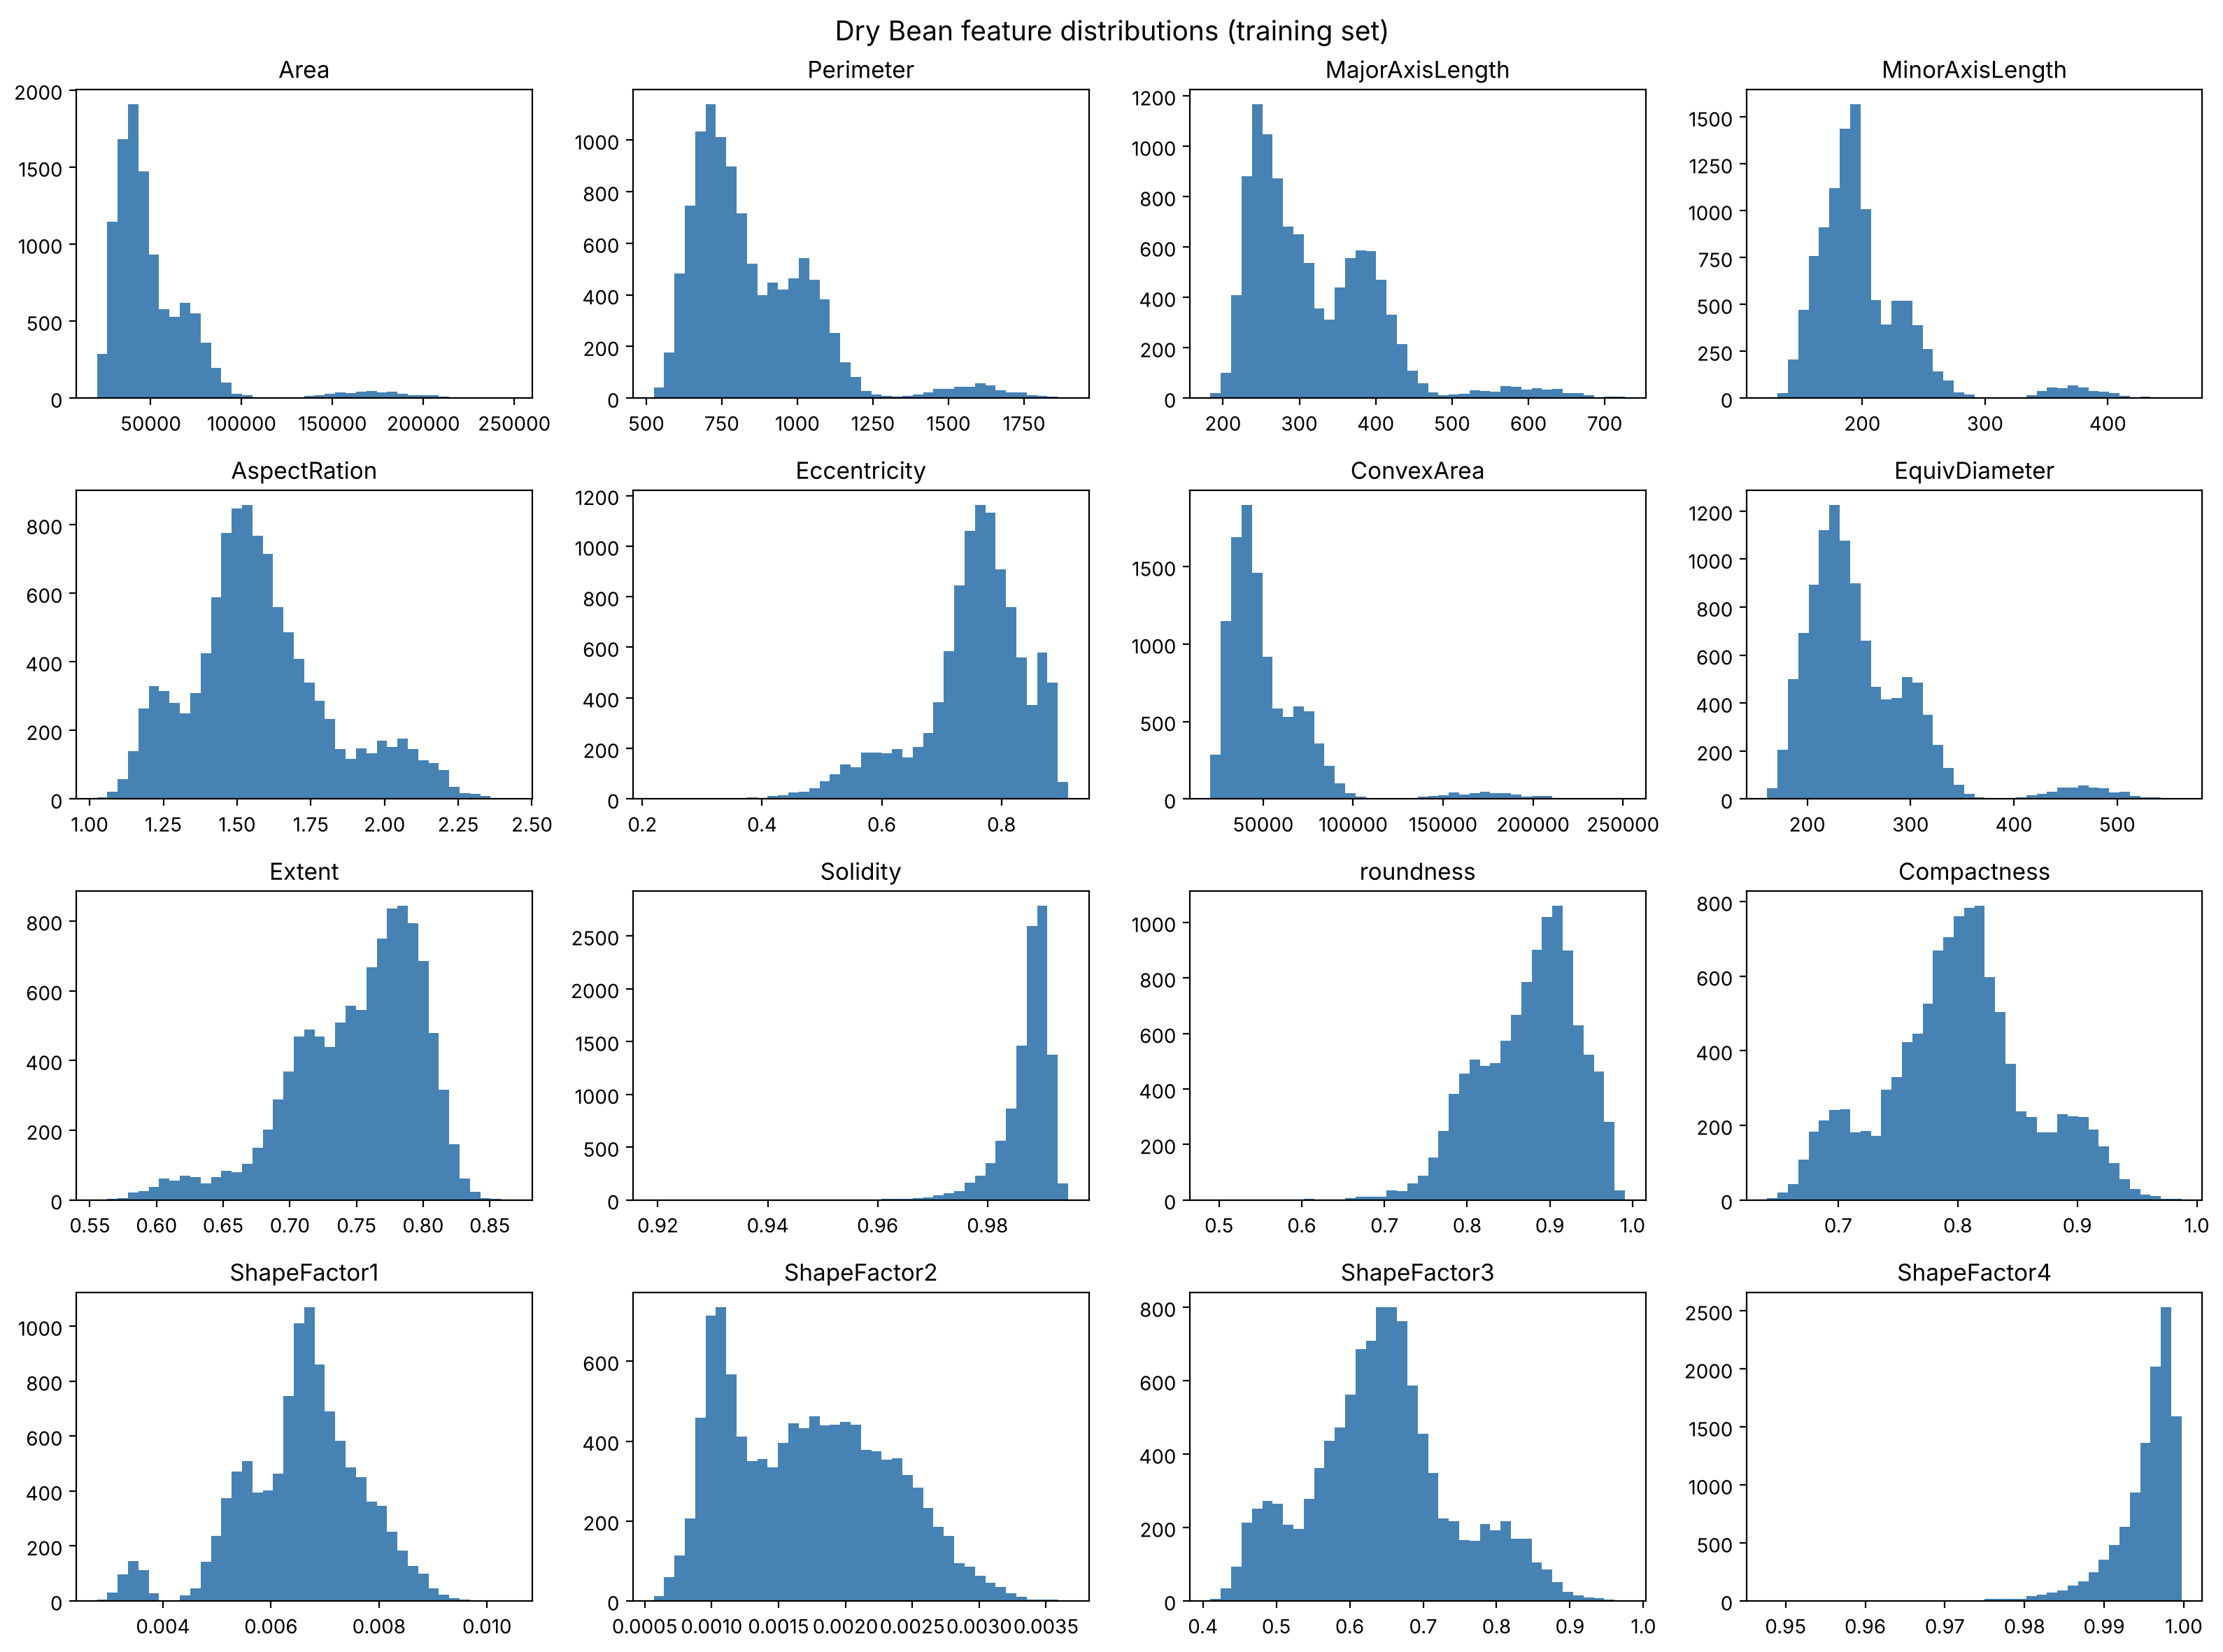

In [10]:
plot_histograms(X_train, "Dry Bean feature distributions (training set)",
                "fig02_drybean_histograms.png")

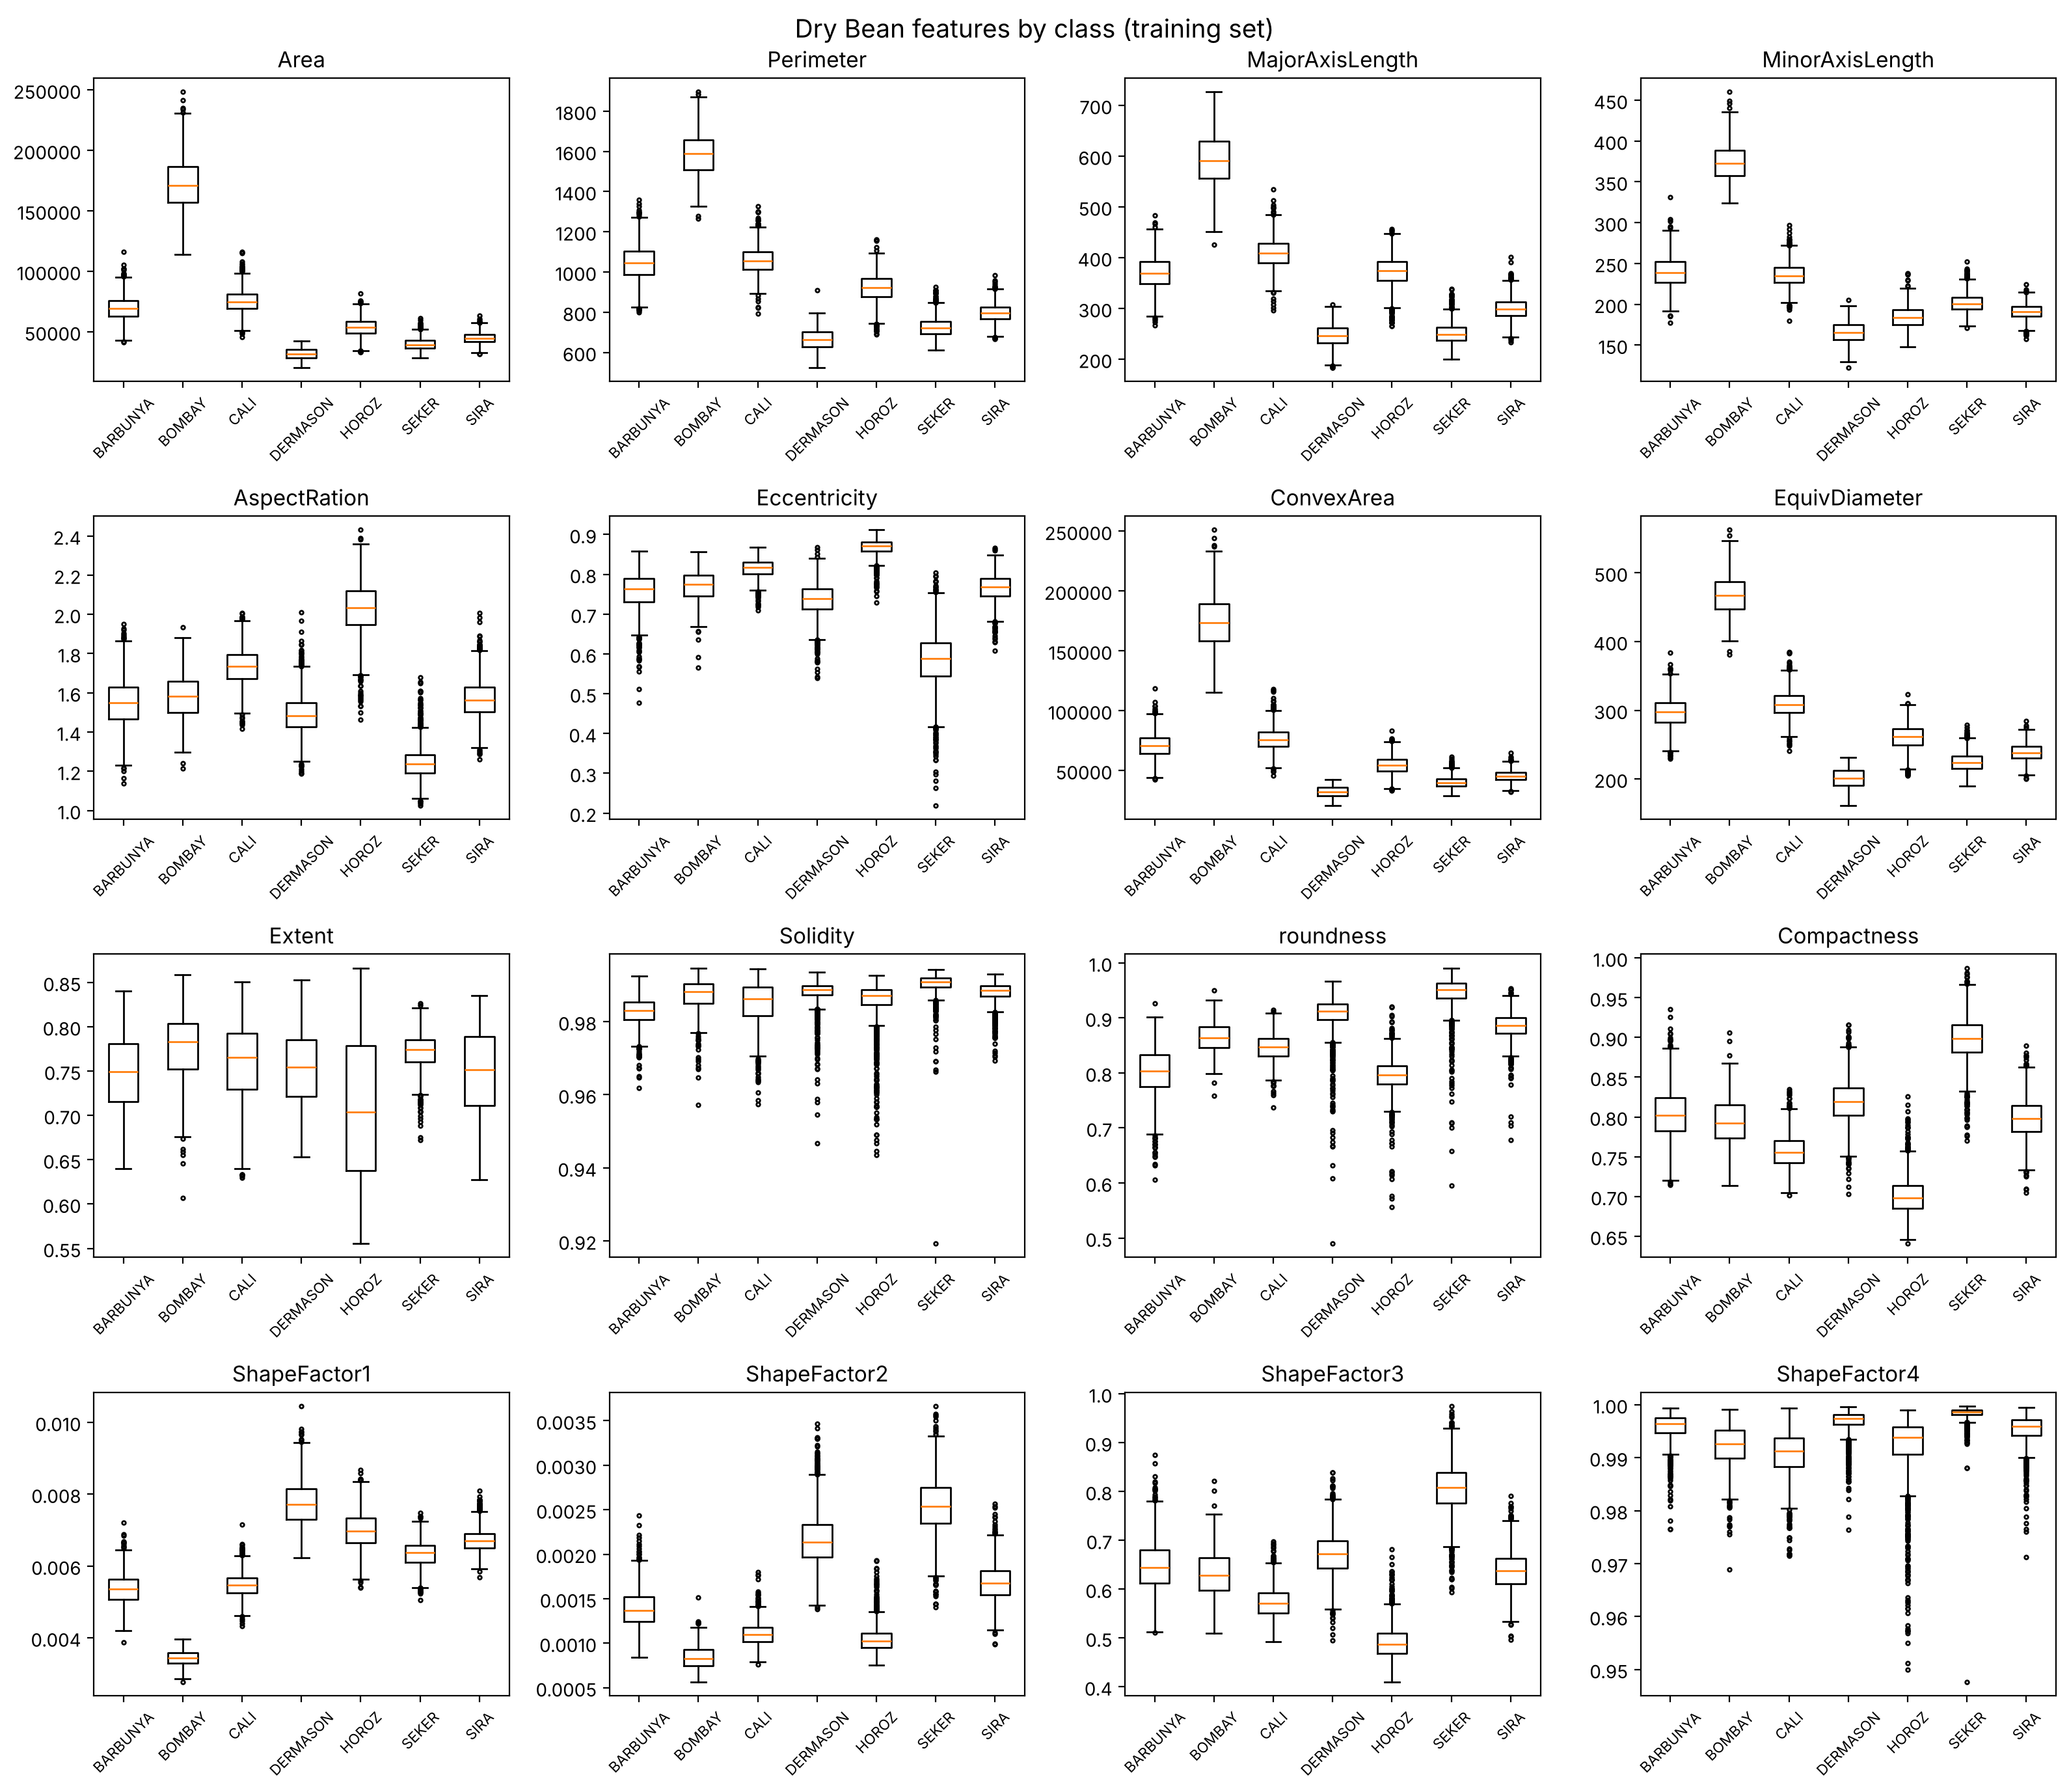

In [11]:
y_train_names = pd.Series(class_names[y_train], index=X_train.index)
plot_boxplots(X_train, y_train_names, "Dry Bean features by class (training set)",
              "fig03_drybean_boxplots.png")

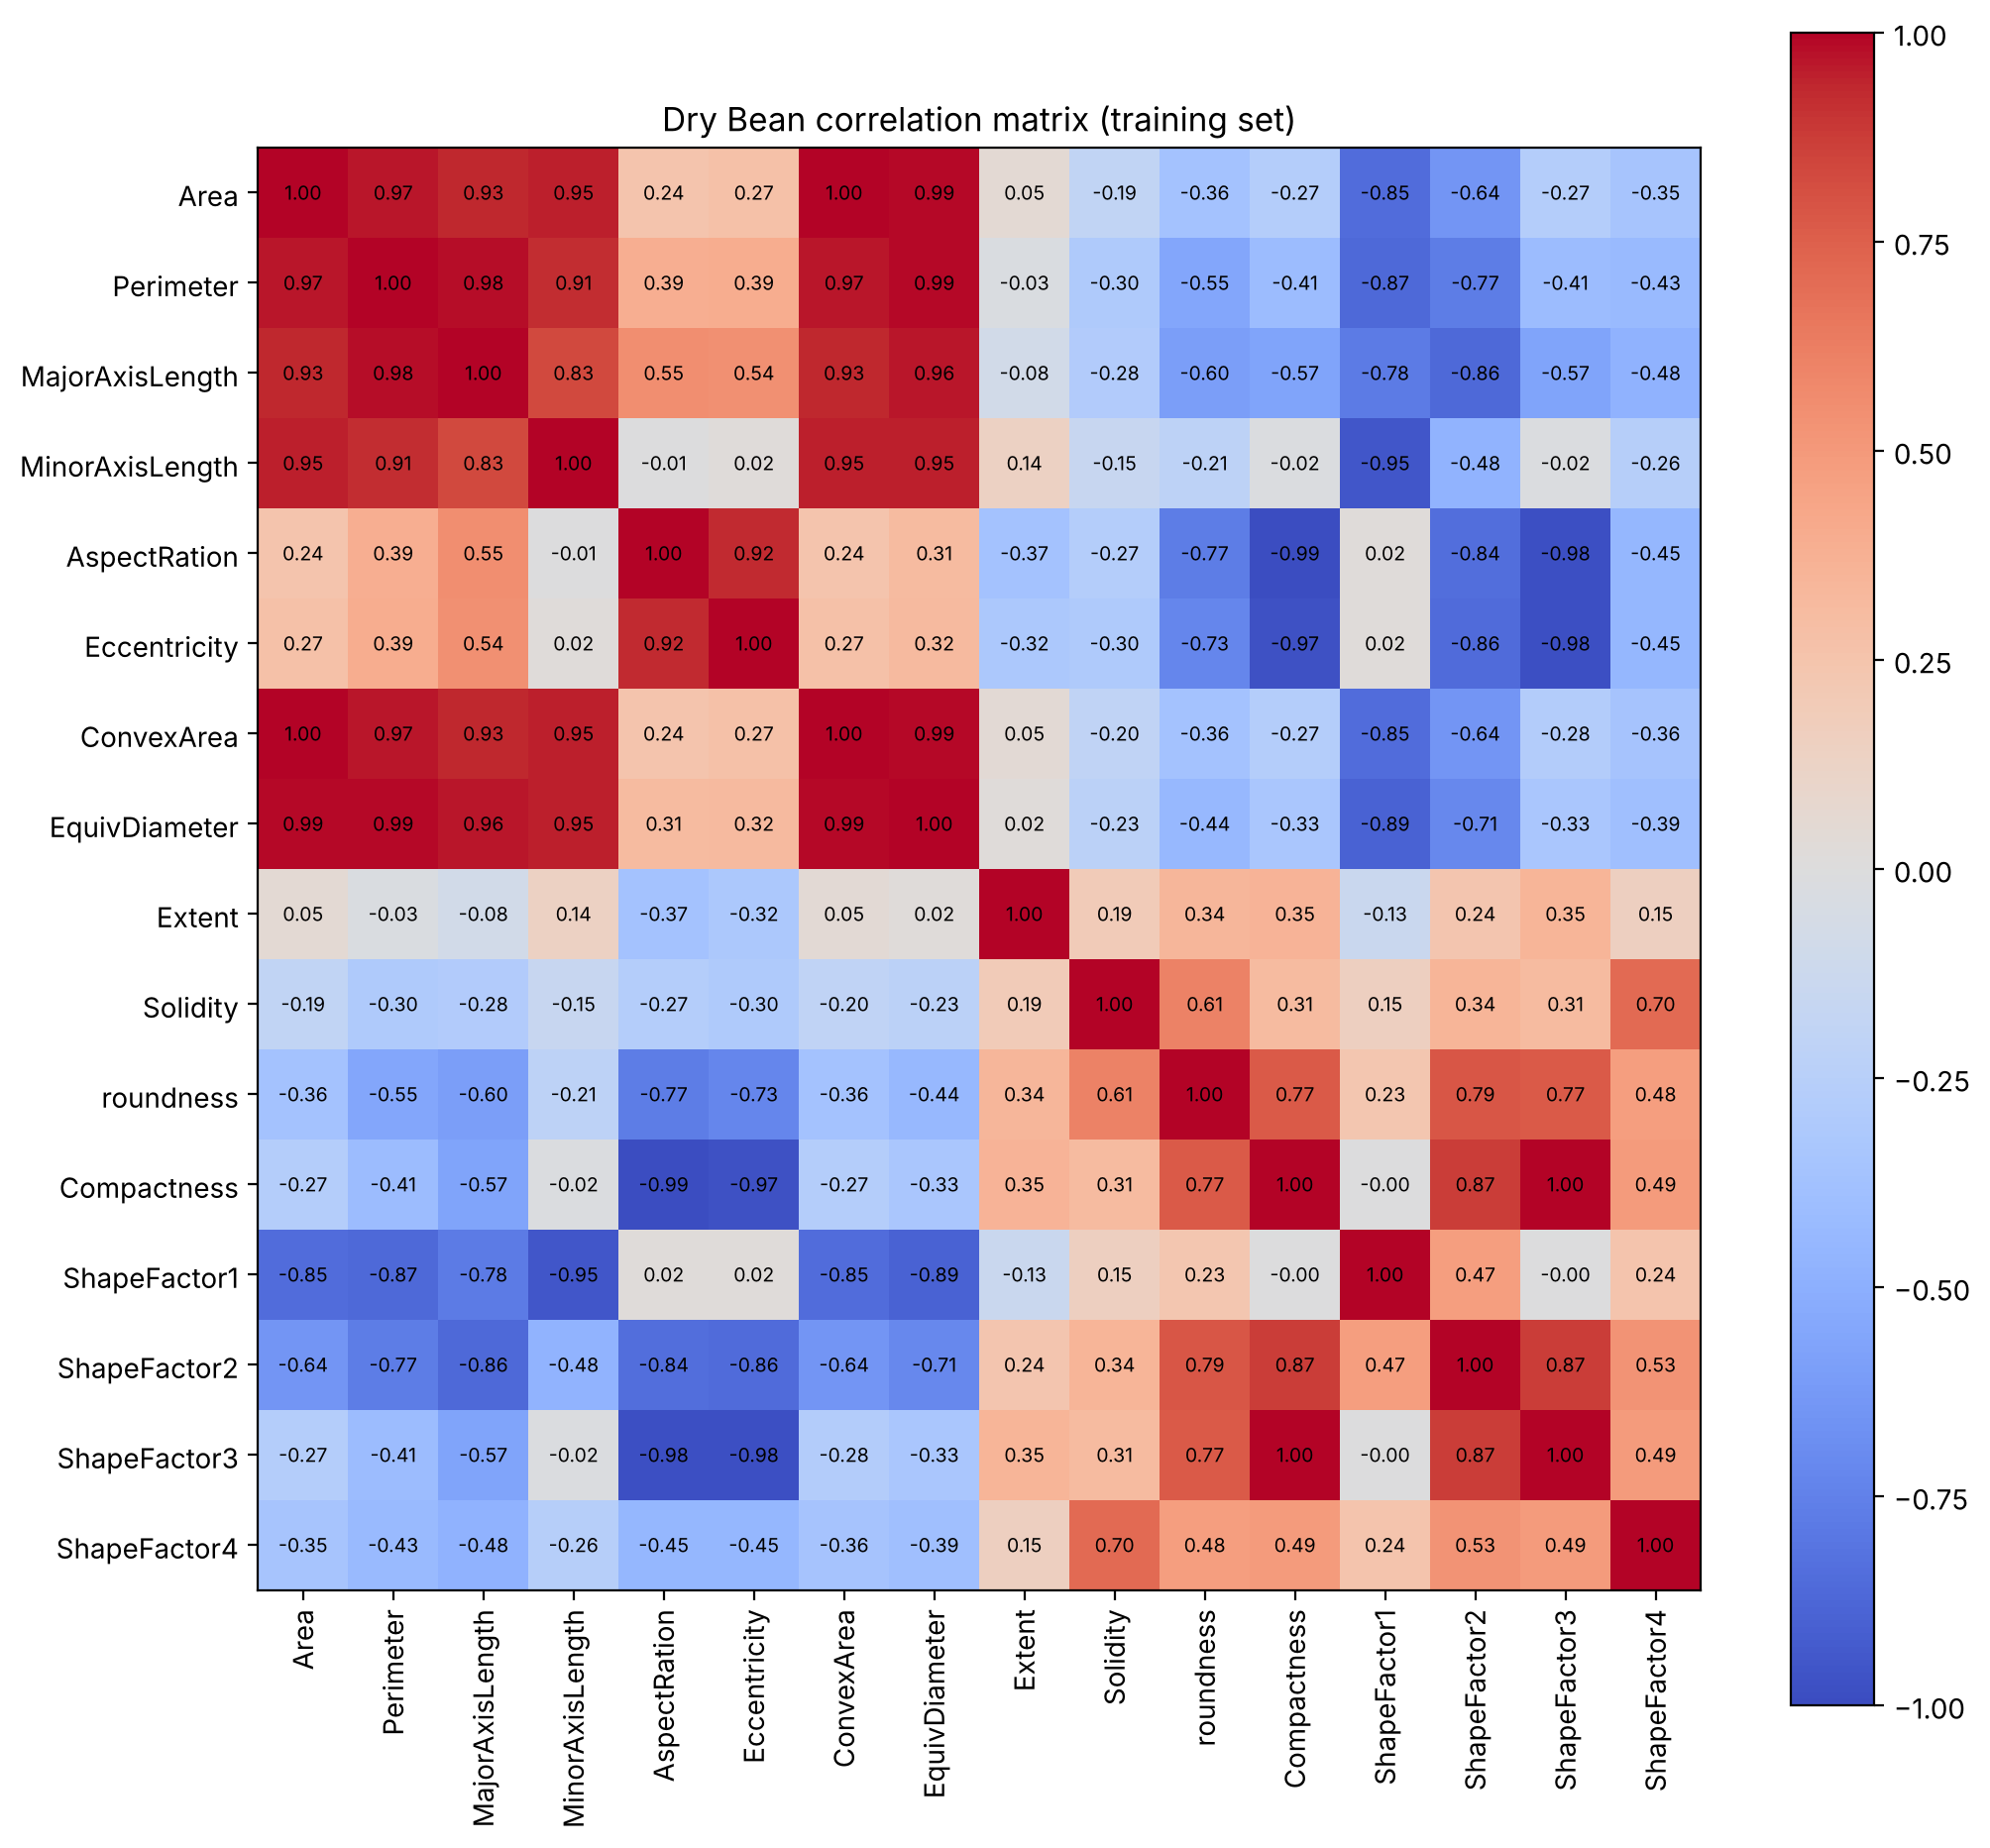

In [12]:
corr = plot_correlation(X_train, "Dry Bean correlation matrix (training set)",
                        "fig04_drybean_correlation.png")

In [13]:
# list the feature pairs with |correlation| > 0.95
pairs = []
for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        if abs(corr.iloc[i, j]) > 0.95:
            pairs.append((corr.columns[i], corr.columns[j], round(corr.iloc[i, j], 3)))
pd.DataFrame(pairs, columns=["Feature 1", "Feature 2", "Correlation"])

,Feature 1,Feature 2,Correlation
0,Area,Perimeter,0.967
1,Area,MinorAxisLength,0.952
2,Area,ConvexArea,1.000
3,Area,EquivDiameter,0.985
4,Perimeter,MajorAxisLength,0.978
5,Perimeter,ConvexArea,0.968
6,Perimeter,EquivDiameter,0.992
7,MajorAxisLength,EquivDiameter,0.962
8,MinorAxisLength,ConvexArea,0.952
9,AspectRation,Compactness,-0.988


In [14]:
# outliers: number of points outside 1.5*IQR (training set)
count_outliers(X_train)

Eccentricity       684
Solidity           621
ShapeFactor4       616
MinorAxisLength    457
Area               443
ConvexArea         442
ShapeFactor1       428
EquivDiameter      422
Perimeter          405
AspectRation       403
MajorAxisLength    307
Extent             208
ShapeFactor3       164
Compactness        108
roundness           67
ShapeFactor2         0
dtype: int64

**Observations from the EDA and the decisions they lead to:**
1. **Very different scales** (Area goes up to about 250,000 while ShapeFactor2 is around 0.002) -> scaling is
   required for Logistic Regression and SVM. We put the `StandardScaler` inside a Pipeline so it is learned from the training folds only.
2. **Imbalanced classes** (DERMASON 26.2% vs BOMBAY 3.9%) -> stratified split and stratified CV, tuning with
   `f1_macro`, and we do not rely on accuracy alone.
3. **Strong multicollinearity**: Area, ConvexArea, Perimeter and EquivDiameter are almost the same information
   (correlation 0.97 to 1.00), and Compactness and ShapeFactor3 have correlation 0.999. This makes Logistic
   Regression coefficients hard to interpret, and we test removing some of them in Stage 6.
4. **Outliers**: many points fall outside 1.5*IQR (Eccentricity, Solidity, ShapeFactor4), but the boxplots
   (fig03) show they are mostly real beans of a class with a different shape (for example the large BOMBAY beans
   or the round SEKER beans), not measurement errors. So we **keep them**.
5. **BOMBAY is clearly separated** by size (fig03), while DERMASON and SIRA overlap in almost every feature,
   so we expect most errors between DERMASON and SIRA.

## Stage 6: Feature selection (only if there is a reason)
The correlation matrix shows a group of size features that carry almost the same information.
We test, **with cross-validation on the training set only**, whether removing the redundant ones helps.
If it does not help, we keep all 16 features.

In [15]:
redundant = ["ConvexArea", "EquivDiameter", "Perimeter"]   # nearly copies of Area
X_train_reduced = X_train.drop(columns=redundant)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
models = get_models()

rows = []
for name, (pipe, grid) in models.items():
    all_f = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1).mean()
    red_f = cross_val_score(pipe, X_train_reduced, y_train, cv=cv, scoring="f1_macro", n_jobs=-1).mean()
    rows.append([name, round(all_f, 4), round(red_f, 4)])

pd.DataFrame(rows, columns=["Model (default settings)", "CV F1 macro - all 16 features",
                            "CV F1 macro - without " + ", ".join(redundant)])

,Model (default settings),CV F1 macro - all 16 features,"CV F1 macro - without ConvexArea, EquivDiameter, Perimeter"
0,Logistic Regression,0.9365,0.9366
1,Random Forest,0.9341,0.9371
2,SVM,0.9416,0.9421


**Decision:** removing the three redundant size features changes the CV macro F1 by less than 0.004 for every model,
which is about the same as the noise between folds. There is no clear gain, so we **keep all 16 features**
(as planned, we do not drop features only to reduce their number).

## Stage 7: Training and tuning
`GridSearchCV` with `StratifiedKFold(5)` on the training set only, scored with `f1_macro`.

Why these ranges:
- **Logistic Regression - C** (inverse of regularization strength): 0.01 to 100 on a log scale covers strong to weak regularization.
- **Random Forest** - `n_estimators` 100-300 (more trees = more stable, but slower), `max_depth` None/10/20 and
  `min_samples_split` 2/5/10 control how complex each tree can get (overfitting).
- **SVM** - `C` 0.1 to 100 controls how much we punish training errors; `kernel` linear vs rbf;
  `gamma` (rbf only) controls how far the influence of one sample reaches (small = smooth boundary).

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

best_models = {}
tuning_info = {}

for name, (pipe, grid) in get_models().items():
    search, tuning_time = tune_model(pipe, grid, X_train, y_train, cv)
    best_models[name] = search.best_estimator_
    tuning_info[name] = {"best_params": search.best_params_,
                         "cv_f1": search.best_score_,
                         "tuning_time": tuning_time,
                         "fit_time": search.refit_time_}
    print(f"{name}: best params = {clean_params(search.best_params_)}, "
          f"CV F1 macro = {search.best_score_:.4f}, tuning time = {tuning_time:.1f} s")

Logistic Regression: best params = C=100, CV F1 macro = 0.9376, tuning time = 2.5 s


Random Forest: best params = max_depth=20, min_samples_split=10, n_estimators=200, CV F1 macro = 0.9361, tuning time = 278.8 s


SVM: best params = C=10, gamma=scale, kernel=rbf, CV F1 macro = 0.9438, tuning time = 24.6 s


## Stage 8: Final evaluation on the test set
All three tuned models are evaluated on the **same** test set with the **same** metrics.
Precision, Recall and F1 are **macro** averages (each class counts the same, so the small BOMBAY class
matters as much as DERMASON). Weighted F1 is added for comparison.

In [17]:
results = []
for name, model in best_models.items():
    y_pred = model.predict(X_test)
    row = {"Model": name}
    row.update(get_scores(y_test, y_pred))
    row["Best Params"] = clean_params(tuning_info[name]["best_params"])
    row["Training Time (s)"] = round(tuning_info[name]["fit_time"], 3)
    row["Tuning Time (s)"] = round(tuning_info[name]["tuning_time"], 1)
    results.append(row)

results_df = pd.DataFrame(results)
results_df.to_csv(TABLE_DIR + "drybean_results.csv", index=False)
results_df.round(4)

,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted),Best Params,Training Time (s),Tuning Time (s)
0,Logistic Regression,0.9192,0.9310,0.9295,0.9301,0.9193,C=100,0.489,2.5
1,Random Forest,0.9184,0.9315,0.9288,0.9300,0.9183,"max_depth=20, min_samples_split=10, n_estimato...",5.469,278.8
2,SVM,0.9236,0.9356,0.9340,0.9347,0.9236,"C=10, gamma=scale, kernel=rbf",0.439,24.6


**Training Time** is the time to fit the final model once with the best parameters.
**Tuning Time** is the time of the whole grid search.

### Overfitting check
We compare the macro F1 on the training set, in cross-validation and on the test set.
A large gap between train and test means overfitting.

In [18]:
gap_rows = []
for name, model in best_models.items():
    train_f1 = f1_score(y_train, model.predict(X_train), average="macro")
    test_f1 = f1_score(y_test, model.predict(X_test), average="macro")
    gap_rows.append([name, train_f1, tuning_info[name]["cv_f1"], test_f1, train_f1 - test_f1])

gap_df = pd.DataFrame(gap_rows, columns=["Model", "Train F1 (macro)", "CV F1 (macro)",
                                         "Test F1 (macro)", "Train - Test gap"])
gap_df.to_csv(TABLE_DIR + "drybean_overfitting.csv", index=False)
gap_df.round(4)

,Model,Train F1 (macro),CV F1 (macro),Test F1 (macro),Train - Test gap
0,Logistic Regression,0.9402,0.9376,0.9301,0.0100
1,Random Forest,0.9820,0.9361,0.9300,0.0520
2,SVM,0.9509,0.9438,0.9347,0.0161


**Observations (Table above):**
- **SVM (rbf, C=10, gamma=scale) is the best model** on every metric: accuracy 0.924 and macro F1 0.935.
  Logistic Regression and Random Forest are very close (macro F1 about 0.930). The difference is small (about 0.5%).
- Macro F1 is higher than accuracy here because the easy small class BOMBAY (F1 = 1.00) counts as much as the
  large classes, while the hardest class (SIRA) is large.
- **Overfitting:** Random Forest has the largest gap (train F1 0.982 vs test 0.930), because its trees can almost
  memorize the training set. Logistic Regression has the smallest gap (0.010) because it is a simple linear model
  (higher bias, lower variance). SVM is in between.
- The CV scores are close to the test scores for every model, so the CV estimate was reliable.
- Logistic Regression chose C=100, the edge of the grid (the weakest regularization we tried). This means it
  wants a more flexible boundary; a larger C would likely give only a very small change.
- Training time: SVM and LR fit in under 1 second, Random Forest needs about 5 seconds and its grid search was the slowest (about 4.5 minutes).

### Confusion matrices (fig05 to fig07)

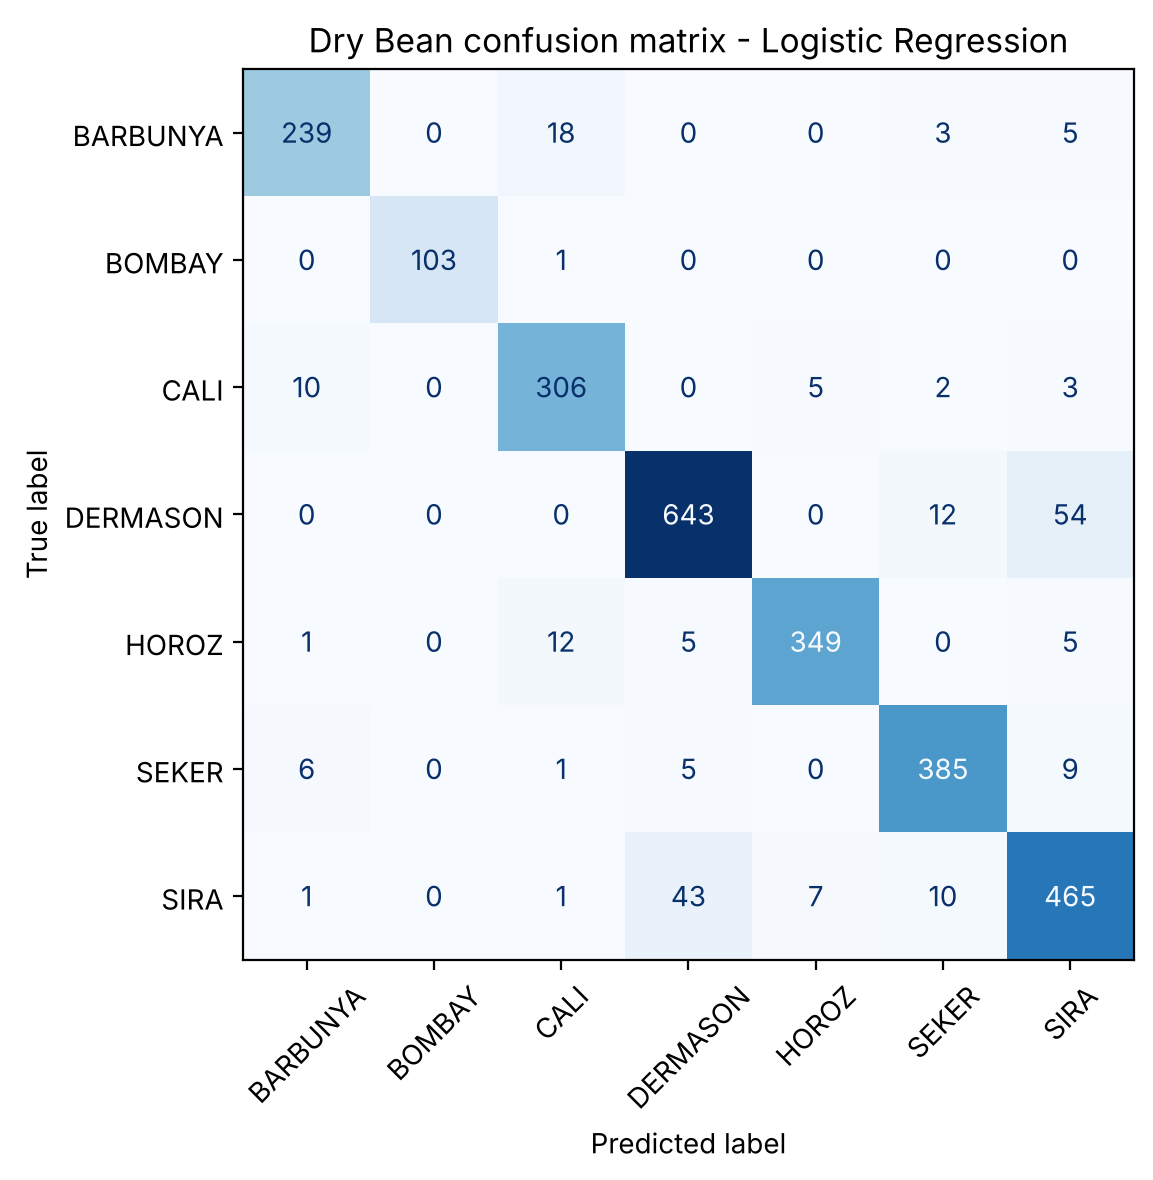

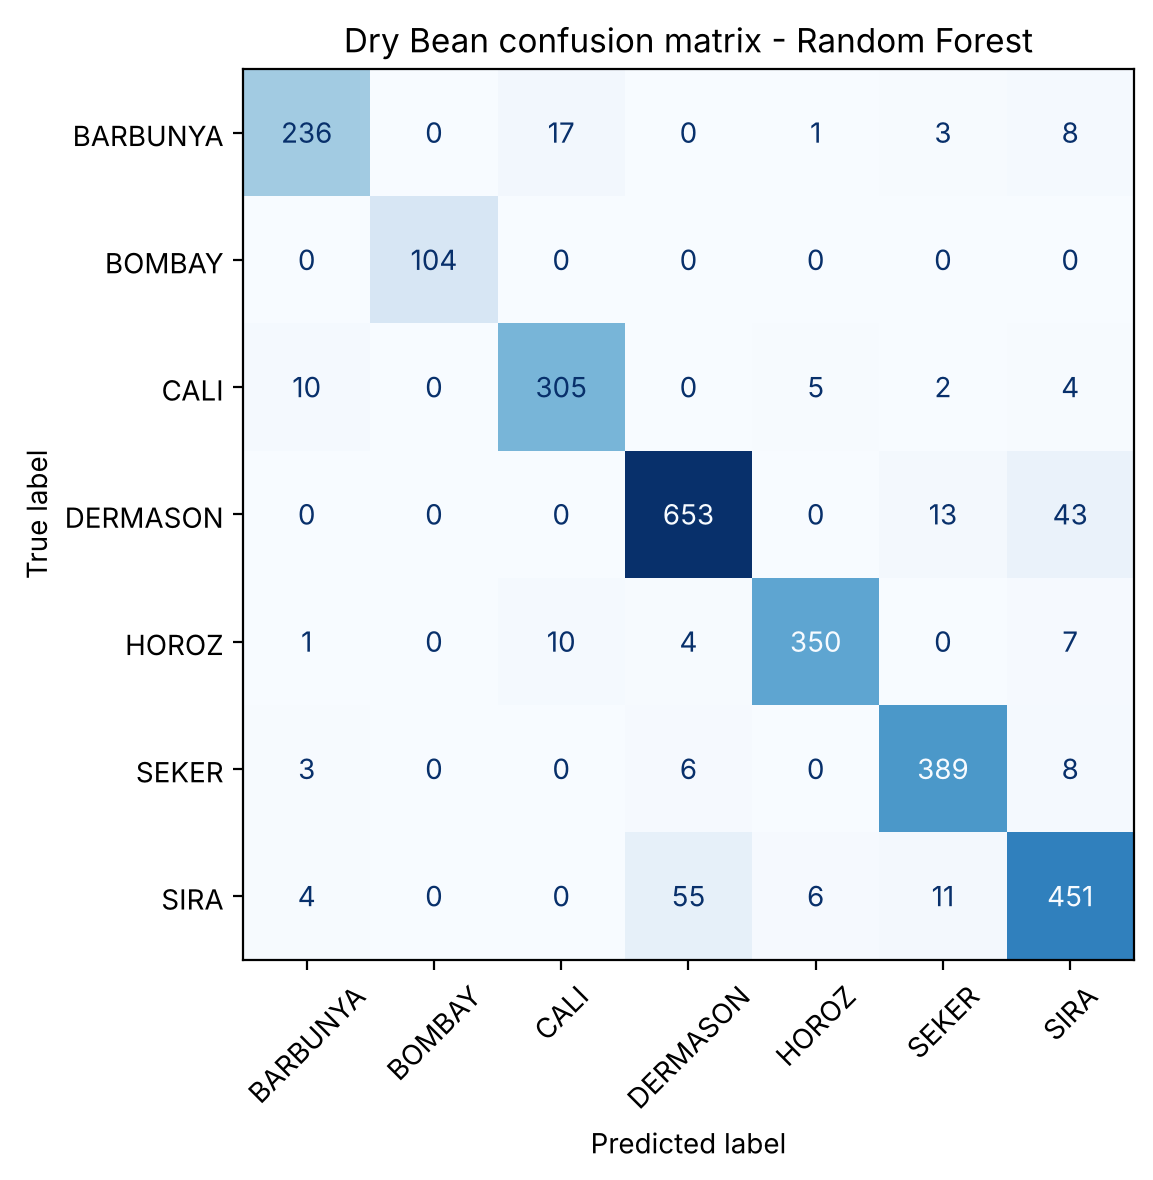

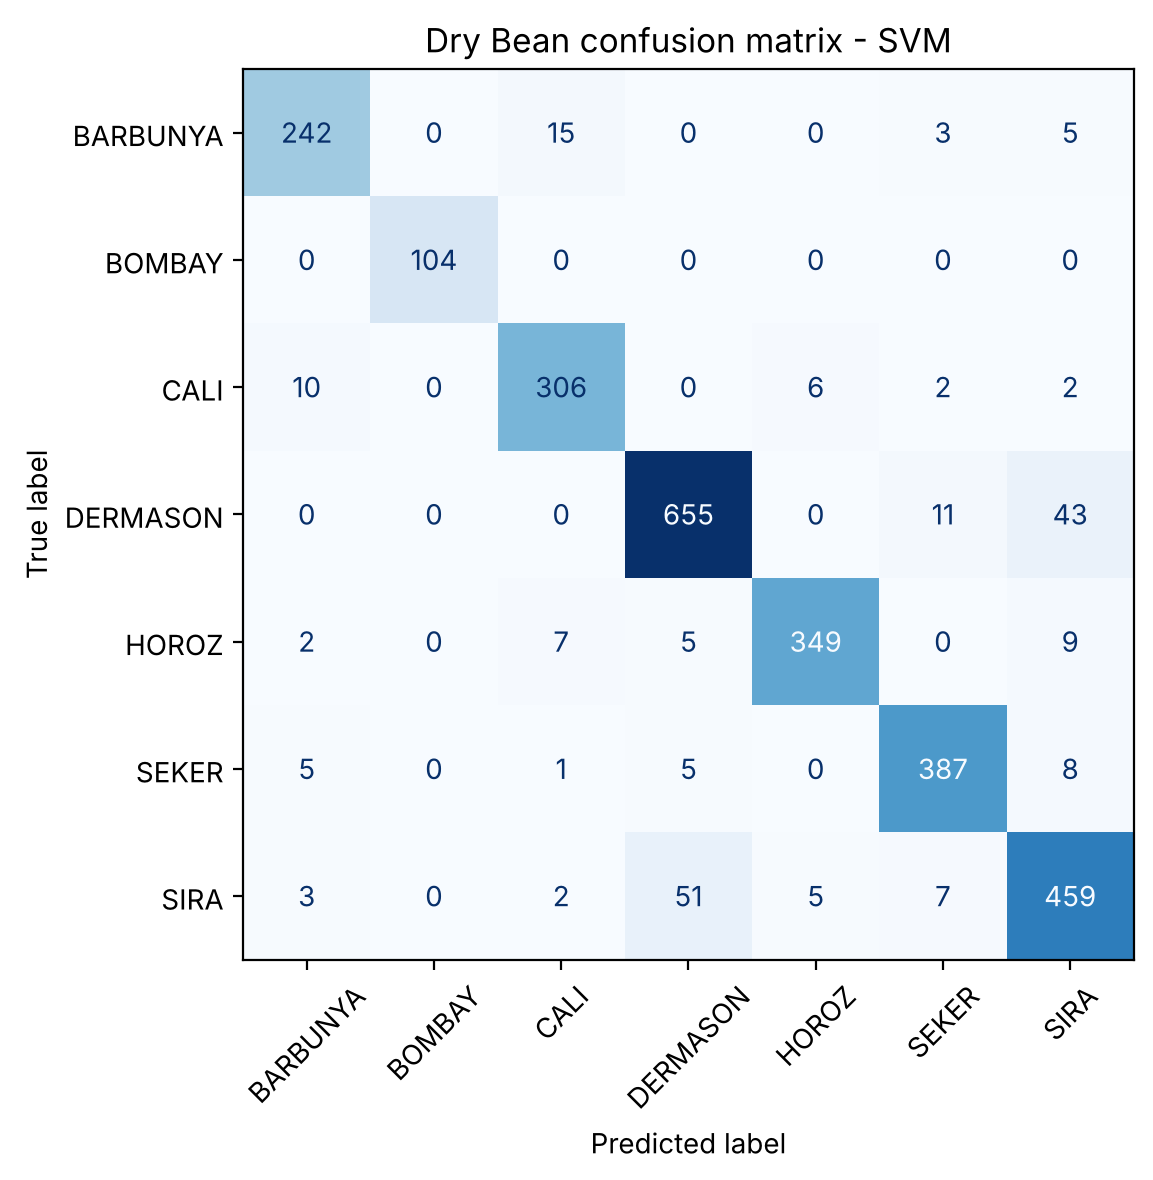

In [19]:
fig_num = 5
for name, model in best_models.items():
    short = name.lower().replace(" ", "_")
    plot_confusion(model, X_test, y_test, class_names,
                   f"Dry Bean confusion matrix - {name}",
                   f"fig{fig_num:02d}_drybean_cm_{short}.png")
    fig_num += 1

In [20]:
# which pairs of classes are confused the most? (sum of both directions, all three models)
from sklearn.metrics import confusion_matrix

confused = {}
for name, model in best_models.items():
    cm = confusion_matrix(y_test, model.predict(X_test))
    for i in range(len(class_names)):
        for j in range(i + 1, len(class_names)):
            pair = class_names[i] + " - " + class_names[j]
            confused[pair] = confused.get(pair, 0) + cm[i, j] + cm[j, i]

pd.Series(confused).sort_values(ascending=False).head(5).rename("Errors (3 models together)")

DERMASON - SIRA     289
BARBUNYA - CALI      80
SEKER - SIRA         53
DERMASON - SEKER     52
CALI - HOROZ         45
Name: Errors (3 models together), dtype: int64

In [21]:
# per-class results of the best model
from sklearn.metrics import classification_report

best_name = results_df.sort_values("F1 (macro)", ascending=False).iloc[0]["Model"]
print("Best model on Dry Bean:", best_name, "\n")
print(classification_report(y_test, best_models[best_name].predict(X_test),
                            target_names=class_names, digits=3))

Best model on Dry Bean: SVM 



              precision    recall  f1-score   support

    BARBUNYA      0.924     0.913     0.918       265
      BOMBAY      1.000     1.000     1.000       104
        CALI      0.924     0.939     0.932       326
    DERMASON      0.915     0.924     0.919       709
       HOROZ      0.969     0.938     0.954       372
       SEKER      0.944     0.953     0.949       406
        SIRA      0.873     0.871     0.872       527

    accuracy                          0.924      2709
   macro avg      0.936     0.934     0.935      2709
weighted avg      0.924     0.924     0.924      2709



**Which classes are confused and why:**
- **DERMASON - SIRA** is by far the most common error (289 errors across the three models). In fig03 these two
  classes have overlapping boxes in almost every feature: they have a similar size and a similar shape.
- **BARBUNYA - CALI** comes second: both are large beans with similar size features.
- **BOMBAY is never confused** (F1 = 1.00) because it is much larger than every other bean.
- SIRA has the lowest F1 (0.872) of all classes for the best model.

## Stage 9: Feature importance
- Logistic Regression: coefficients (the features were scaled, so the sizes can be compared).
- Random Forest: `feature_importances_` and permutation importance.
- SVM: permutation importance (an rbf SVM has no coefficients).

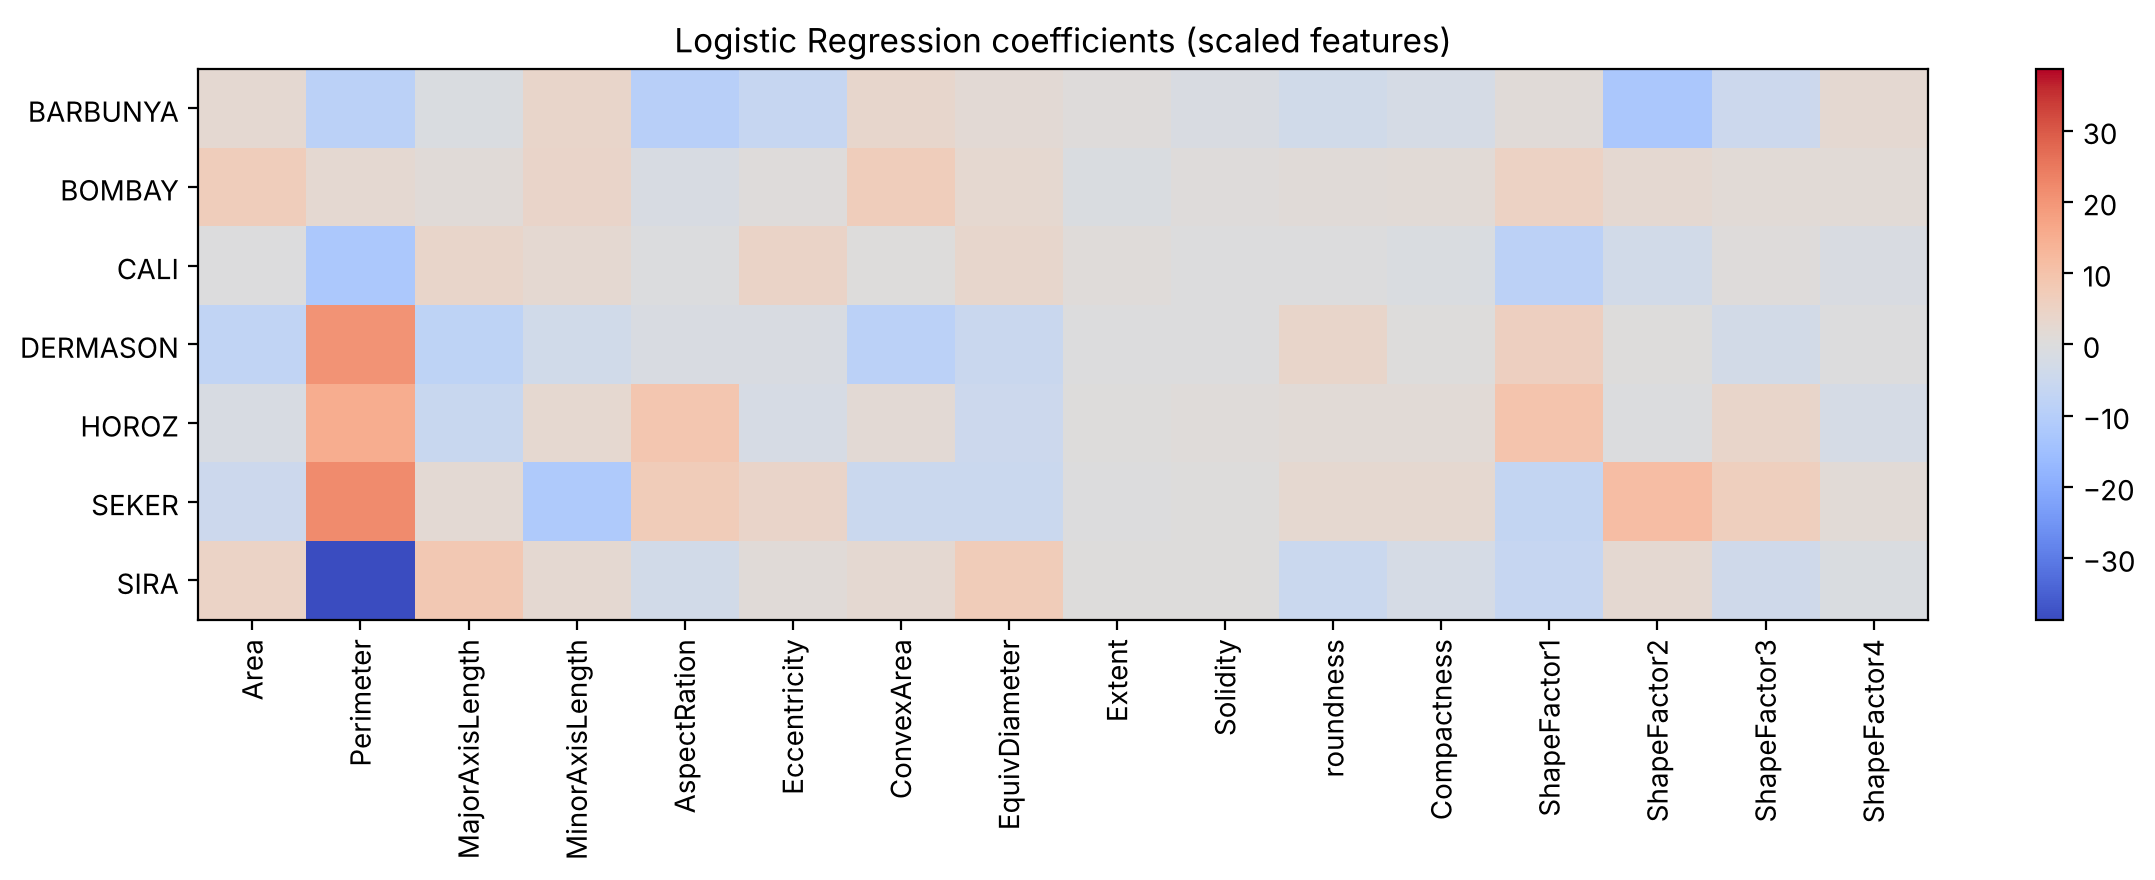

Perimeter          17.10
ShapeFactor1        6.08
AspectRation        4.59
ShapeFactor2        4.53
MinorAxisLength     4.26
MajorAxisLength     4.26
EquivDiameter       4.24
ConvexArea          3.96
Area                3.94
ShapeFactor3        3.23
Eccentricity        2.79
roundness           2.48
Compactness         1.61
ShapeFactor4        1.37
Solidity            0.47
Extent              0.41
dtype: float64

In [22]:
# fig08: Logistic Regression coefficients (one row per class)
lr = best_models["Logistic Regression"].named_steps["model"]
coef = pd.DataFrame(lr.coef_, index=class_names, columns=X.columns)

fig, ax = plt.subplots(figsize=(12, 4.5))
lim = np.abs(coef.values).max()
im = ax.imshow(coef, cmap="coolwarm", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(len(X.columns)))
ax.set_xticklabels(X.columns, rotation=90)
ax.set_yticks(range(len(class_names)))
ax.set_yticklabels(class_names)
plt.colorbar(im)
ax.set_title("Logistic Regression coefficients (scaled features)")
plt.tight_layout()
plt.savefig(FIG_DIR + "fig08_drybean_lr_coefficients.png", dpi=150)
plt.show()

# mean absolute coefficient per feature
coef.abs().mean().sort_values(ascending=False).round(2)

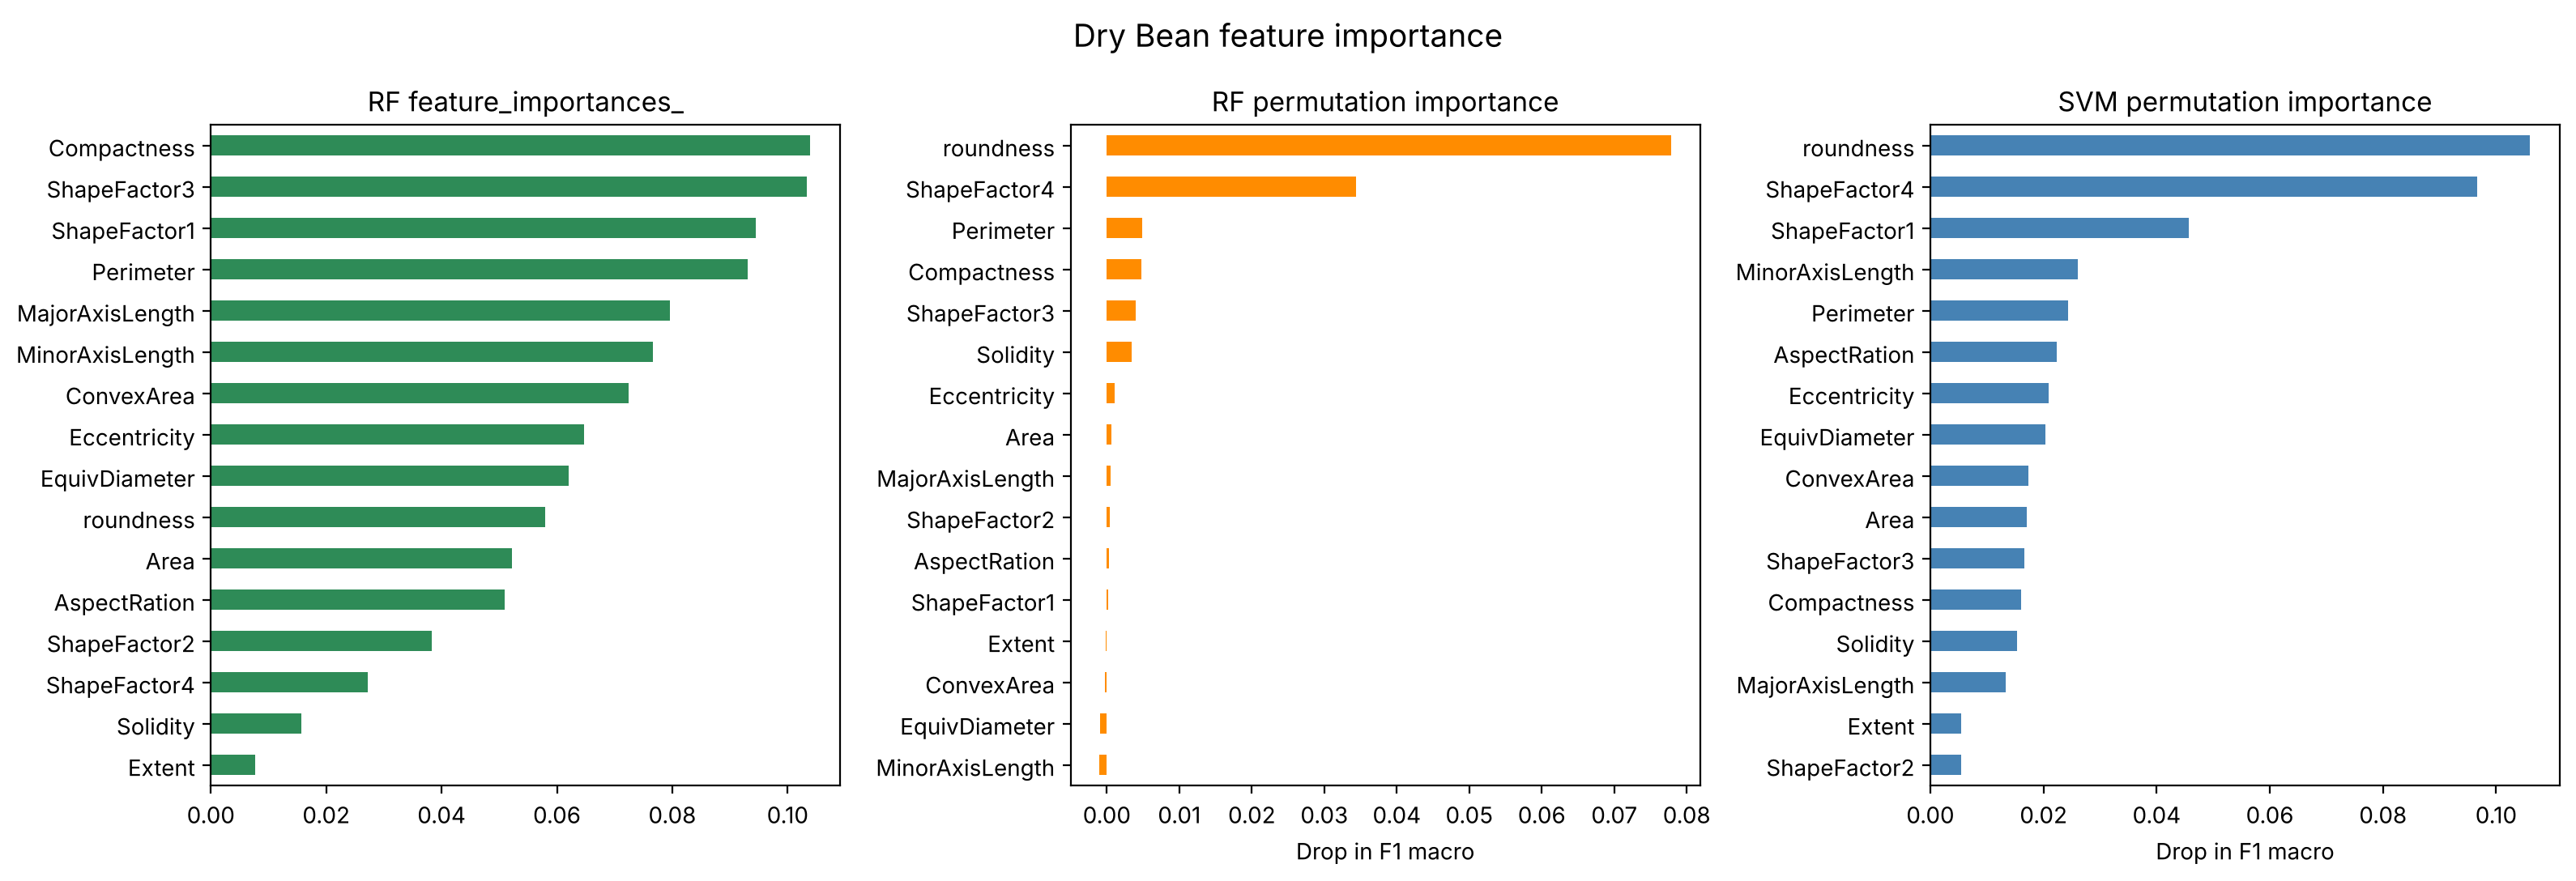

In [23]:
rf = best_models["Random Forest"].named_steps["model"]
rf_imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
rf_perm = get_permutation_importance(best_models["Random Forest"], X_test, y_test)
svm_perm = get_permutation_importance(best_models["SVM"], X_test, y_test)

# fig09: three importance measures side by side
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
rf_imp.plot.barh(ax=axes[0], color="seagreen", title="RF feature_importances_")
rf_perm.plot.barh(ax=axes[1], color="darkorange", title="RF permutation importance")
svm_perm.plot.barh(ax=axes[2], color="steelblue", title="SVM permutation importance")
for ax in axes[1:]:
    ax.set_xlabel("Drop in F1 macro")
fig.suptitle("Dry Bean feature importance", fontsize=14)
plt.tight_layout()
plt.savefig(FIG_DIR + "fig09_drybean_feature_importance.png", dpi=150)
plt.show()

**Discussion of feature importance:**
- **The three methods do not agree**, and this is mainly because of the correlated features:
  - Random Forest `feature_importances_` spreads the importance over groups of correlated features
    (Compactness and ShapeFactor3 are almost the same feature and both rank high).
  - **Permutation importance** shuffles one feature at a time. If a correlated "copy" of that feature still exists,
    the model can use the copy, so the drop is small. This is why ConvexArea, EquivDiameter and Area get almost zero
    permutation importance for Random Forest even though size clearly separates the classes (fig03).
  - For Logistic Regression, **Perimeter has a very large coefficient** (mean |coef| 17.1, three times the next one).
    This does not mean Perimeter alone is that important: with highly correlated inputs the model can give large
    opposite weights to features that cancel each other out. Coefficients are only safe to interpret when features
    are scaled **and** not strongly correlated.
- **roundness and ShapeFactor4** are the most important features for both RF and SVM by permutation. These shape
  features are not copies of the size features, so shuffling them really hurts the model. This makes sense: DERMASON,
  SIRA and SEKER have similar sizes and are separated mainly by how round the bean is.

In [24]:
# save the best parameters so 03_comparison.ipynb can reuse them
import json
params = {name: info["best_params"] for name, info in tuning_info.items()}
with open(TABLE_DIR + "drybean_best_params.json", "w") as f:
    json.dump(params, f, indent=2, default=str)
print(params)

{'Logistic Regression': {'model__C': 100}, 'Random Forest': {'model__max_depth': 20, 'model__min_samples_split': 10, 'model__n_estimators': 200}, 'SVM': {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'rbf'}}
